In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import kstest

ticker = "SPY"
start ="2000-1-1"
end = "2026-1-1"
interval = "1d"

spy = yf.download(
    ticker,
    start,
    end,
    interval,
    auto_adjust=True
)
price = spy["Close"]["SPY"]                                     ###This is because the column of close of spy has an entry of spy in it. To calculate it properly we write it this way.
spy["Returns"] = spy["Close"]["SPY"].pct_change()
spy["Log Returns"] = np.log(price/price.shift(1))
spy = spy.dropna()
returns = spy["Log Returns"]

spy[["Returns", "Log Returns"]].tail()

plt.hist(spy["Log Returns"])
plt.xlabel("Log Return Ditribution")
plt.show()

print(spy["Log Returns"].quantile([0.001, 0.005, 0.01, 0.05,
                             0.95, 0.99, 0.995, 0.999]))
mean= spy["Log Returns"].mean()
std = spy["Log Returns"].std()
print("Mean:",mean,"\nStandard Deviation:",std)

In [ ]:
z = stats.norm.ppf(0.001)

threshold = mean + (z*std)

print(threshold)

-0.03745762651509722


In [ ]:
loss = -returns
quantiles = [0.90, 0.925, 0.95, 0.975, 0.99]
loss = loss.squeeze()

quantiles = [0.90, 0.925, 0.95, 0.975, 0.99,0.995]

for q in quantiles:
    threshold = loss.quantile(q)
    exceedances = loss[loss > threshold]

    print(
        f"{q:.1%} threshold = {threshold:.4%}, "
        f"exceedances = {len(exceedances)}"
    )

90.0% threshold = 1.2627%, exceedances = 654
92.5% threshold = 1.5301%, exceedances = 491
95.0% threshold = 1.9208%, exceedances = 327
97.5% threshold = 2.5186%, exceedances = 164
99.0% threshold = 3.4650%, exceedances = 66
99.5% threshold = 4.4868%, exceedances = 33


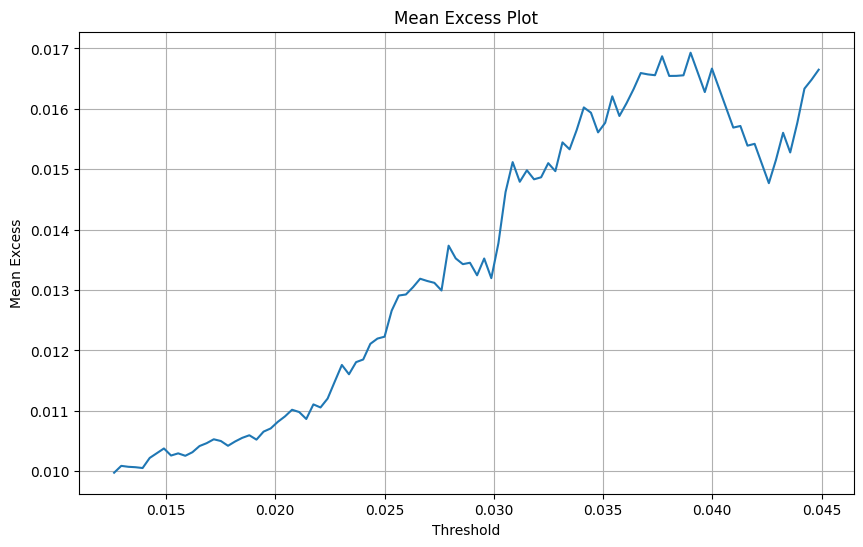

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

thresholds = np.linspace(
    loss.quantile(0.90),
    loss.quantile(0.995),
    100
)

mean_excess = []
n_exceedances = []

for u in thresholds:
    excesses = loss[loss > u] - u

    mean_excess.append(excesses.mean())
    n_exceedances.append(len(excesses))

plt.figure(figsize=(10, 6))
plt.plot(thresholds, mean_excess)
plt.xlabel("Threshold")
plt.ylabel("Mean Excess")
plt.title("Mean Excess Plot")
plt.grid(True)
plt.show()

In [ ]:
from scipy.stats import genpareto
candidate_quantiles = [0.95, 0.975, 0.99, 0.995]

results = []

for q in candidate_quantiles:

    u = loss.quantile(q)

    excesses = loss[loss > u] - u

    shape, loc, scale = genpareto.fit(excesses, floc=0)

    results.append({
        "Quantile": q,
        "Threshold": u,
        "Exceedances": len(excesses),
        "Shape": shape,
        "Scale": scale
    })

gpd_results=(pd.DataFrame(results))
print(gpd_results)

   Quantile  Threshold  Exceedances     Shape     Scale
0     0.950   0.019208          327  0.233363  0.008123
1     0.975   0.025186          164  0.243305  0.009484
2     0.990   0.034650           66  0.130785  0.013709
3     0.995   0.044868           33  0.266129  0.012560


In [ ]:
import numpy as np
from scipy.stats import genpareto

u = loss.quantile(0.95)

excesses = loss[loss > u] - u

n_bootstrap = 2000

bootstrap_shapes = []

for i in range(n_bootstrap):

    sample = np.random.choice(
        excesses,
        size=len(excesses),
        replace=True
    )

    shape, loc, scale = genpareto.fit(
        sample,
        floc=0
    )

    bootstrap_shapes.append(shape)

lower = np.percentile(bootstrap_shapes, 2.5)
upper = np.percentile(bootstrap_shapes, 97.5)

print("Original shape:", genpareto.fit(excesses, floc=0)[0])
print("95% Bootstrap CI:", lower, upper)

Original shape: 0.2333335623497525
95% Bootstrap CI: 0.11273330999157766 0.34955531682214835


In [ ]:
import numpy as np
from scipy.stats import genpareto

u = loss.quantile(0.975)

excesses = loss[loss > u] - u

n_bootstrap = 2000

bootstrap_shapes = []

for i in range(n_bootstrap):

    sample = np.random.choice(
        excesses,
        size=len(excesses),
        replace=True
    )

    shape, loc, scale = genpareto.fit(
        sample,
        floc=0
    )

    bootstrap_shapes.append(shape)

lower = np.percentile(bootstrap_shapes, 2.5)
upper = np.percentile(bootstrap_shapes, 97.5)

print("Original shape:", genpareto.fit(excesses, floc=0)[0])
print("97.5% Bootstrap CI:", lower, upper)

Original shape: 0.2432242339196205
97.5% Bootstrap CI: 0.06350994605854576 0.4271382181394445


In [ ]:
import numpy as np
from scipy.stats import genpareto

u = loss.quantile(0.99)

excesses = loss[loss > u] - u

n_bootstrap = 2000

bootstrap_shapes = []

for i in range(n_bootstrap):

    sample = np.random.choice(
        excesses,
        size=len(excesses),
        replace=True
    )

    shape, loc, scale = genpareto.fit(
        sample,
        floc=0
    )

    bootstrap_shapes.append(shape)

lower = np.percentile(bootstrap_shapes, 2.5)
upper = np.percentile(bootstrap_shapes, 97.5)

print("Original shape:", genpareto.fit(excesses, floc=0)[0])
print("99% Bootstrap CI:", lower, upper)



import numpy as np
from scipy.stats import genpareto

u = loss.quantile(0.995)

excesses = loss[loss > u] - u

n_bootstrap = 2000

bootstrap_shapes = []

for i in range(n_bootstrap):

    sample = np.random.choice(
        excesses,
        size=len(excesses),
        replace=True
    )

    shape, loc, scale = genpareto.fit(
        sample,
        floc=0
    )

    bootstrap_shapes.append(shape)

lower = np.percentile(bootstrap_shapes, 2.5)
upper = np.percentile(bootstrap_shapes, 97.5)

print("Original shape:", genpareto.fit(excesses, floc=0)[0])
print("99.5% Bootstrap CI:", lower, upper)

Original shape: 0.13085986433041807
99% Bootstrap CI: -0.12187527165123338 0.3612617535173748
Original shape: 0.26612861229519885
99.5% Bootstrap CI: -0.3729379746793838 0.8283290572767337


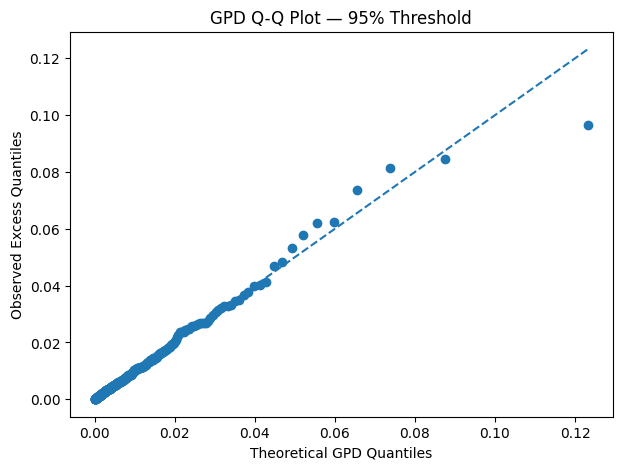

In [ ]:
q = 0.95

u = loss.quantile(q)

excesses = loss[loss > u] - u

shape, loc, scale = genpareto.fit(excesses, floc=0)

n = len(excesses)

empirical_probs = (np.arange(1, n + 1) - 0.5) / n

theoretical_quantiles = genpareto.ppf(
    empirical_probs,
    c=shape,
    loc=0,
    scale=scale
)

observed_quantiles = np.sort(excesses)

plt.figure(figsize=(7, 5))

plt.scatter(
    theoretical_quantiles,
    observed_quantiles
)

min_val = min(theoretical_quantiles.min(), observed_quantiles.min())
max_val = max(theoretical_quantiles.max(), observed_quantiles.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Theoretical GPD Quantiles")
plt.ylabel("Observed Excess Quantiles")
plt.title("GPD Q-Q Plot — 95% Threshold")

plt.show()

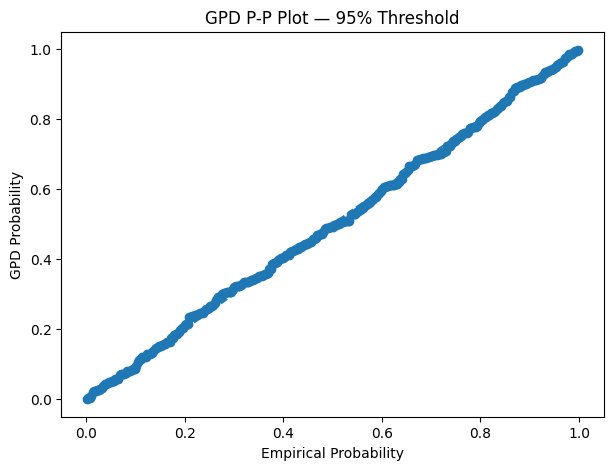

In [ ]:
q = 0.95

u = loss.quantile(q)

excesses = loss[loss > u] - u

shape, loc, scale = genpareto.fit(
    excesses,
    floc=0
)

observed_excesses = np.sort(excesses)

n = len(observed_excesses)

empirical_probs = (
    np.arange(1, n + 1) - 0.5
) / n

theoretical_probs = genpareto.cdf(
    observed_excesses,
    c=shape,
    loc=0,
    scale=scale
)

plt.figure(figsize=(7, 5))

plt.scatter(
    empirical_probs,
    theoretical_probs
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("Empirical Probability")
plt.ylabel("GPD Probability")
plt.title("GPD P-P Plot — 95% Threshold")

plt.show()

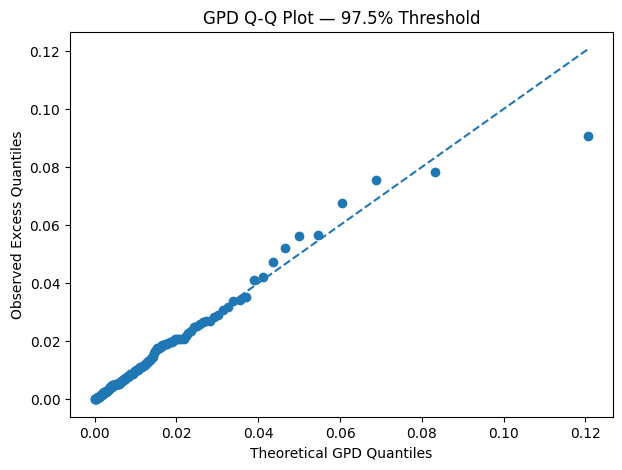

Threshold: 0.025185786423152317
Number of exceedances: 164
Shape: 0.2432242339196205
Scale: 0.009486073809364455


In [ ]:
q = 0.975

u = loss.quantile(q)

excesses = loss[loss > u] - u

shape, loc, scale = genpareto.fit(excesses, floc=0)

n = len(excesses)

empirical_probs = (np.arange(1, n + 1) - 0.5) / n

theoretical_quantiles = genpareto.ppf(
    empirical_probs,
    c=shape,
    loc=0,
    scale=scale
)

observed_quantiles = np.sort(excesses)

plt.figure(figsize=(7, 5))

plt.scatter(
    theoretical_quantiles,
    observed_quantiles
)

min_val = min(theoretical_quantiles.min(), observed_quantiles.min())
max_val = max(theoretical_quantiles.max(), observed_quantiles.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Theoretical GPD Quantiles")
plt.ylabel("Observed Excess Quantiles")
plt.title("GPD Q-Q Plot — 97.5% Threshold")

plt.show()

print("Threshold:", u)
print("Number of exceedances:", len(excesses))
print("Shape:", shape)
print("Scale:", scale)

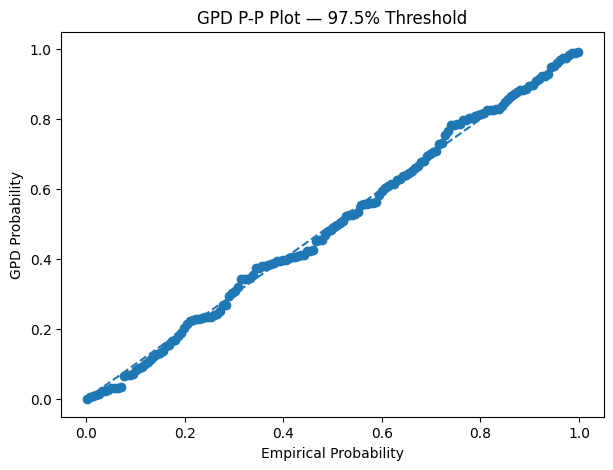

In [ ]:
q = 0.975

u = loss.quantile(q)

excesses = loss[loss > u] - u

shape, loc, scale = genpareto.fit(
    excesses,
    floc=0
)

observed_excesses = np.sort(excesses)

n = len(observed_excesses)

empirical_probs = (
    np.arange(1, n + 1) - 0.5
) / n

theoretical_probs = genpareto.cdf(
    observed_excesses,
    c=shape,
    loc=0,
    scale=scale
)

plt.figure(figsize=(7, 5))

plt.scatter(
    empirical_probs,
    theoretical_probs
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("Empirical Probability")
plt.ylabel("GPD Probability")
plt.title("GPD P-P Plot — 97.5% Threshold")

plt.show()

In [ ]:
gof=gpd_results.iloc[1]
shape_975=gof["Shape"]
exceedances_975=gof["Exceedances"]
scale_975=gof["Scale"]

# 97.5% threshold
u_975 = gof["Threshold"]

# Actual excesses above the threshold
excesses_975 = loss[loss > u_975] - u_975

print("Threshold:", u_975)
print("Number of excesses:", len(excesses_975))
print(excesses_975.head())


Threshold: 0.025185752336148285
Number of excesses: 164
Date
2000-01-04    0.014705
2000-01-24    0.003566
2000-01-28    0.006505
2000-04-12    0.002623
2000-04-14    0.033707
Name: Log Returns, dtype: float64


In [ ]:
ks_stat, ks_pvalue = kstest(
    excesses_975,
    genpareto.cdf,
    args=(shape_975, 0, scale_975)
)

print("Kolmogorov-Smirnov Test")
print("-" * 40)
print(f"KS Statistic : {ks_stat:.4f}")
print(f"P-value      : {ks_pvalue:.4f}")

Kolmogorov-Smirnov Test
----------------------------------------
KS Statistic : 0.0449
P-value      : 0.8801


In [ ]:
import numpy as np

# Sort the observed excesses
x = np.sort(excesses_975.values)

# GPD fitted CDF
F = genpareto.cdf(
    x,
    c=shape_975,
    loc=0,
    scale=scale_975
)

# Avoid log(0) or log(1)
F = np.clip(F, 1e-10, 1 - 1e-10)

n = len(x)

# Anderson-Darling statistic
i = np.arange(1, n + 1)

AD_stat = -n - np.sum(
    (2*i - 1) / n *
    (np.log(F) + np.log(1 - F[::-1]))
)

print("Anderson-Darling Statistic")
print("-" * 40)
print(f"AD Statistic : {AD_stat:.4f}")

Anderson-Darling Statistic
----------------------------------------
AD Statistic : 0.3486


In [ ]:
# Parametric bootstrap for Anderson-Darling GOF

import numpy as np
from scipy.stats import genpareto

np.random.seed(42)

B = 2000
n = len(excesses_975)

# Observed AD statistic
x_obs = np.sort(excesses_975.values)

F_obs = genpareto.cdf(
    x_obs,
    c=shape_975,
    loc=0,
    scale=scale_975
)

F_obs = np.clip(F_obs, 1e-10, 1 - 1e-10)

i = np.arange(1, n + 1)

AD_obs = -n - np.sum(
    (2*i - 1) / n *
    (np.log(F_obs) + np.log(1 - F_obs[::-1]))
)

# Bootstrap AD statistics
AD_boot = []

for _ in range(B):

    # Generate sample from fitted GPD
    simulated = genpareto.rvs(
        c=shape_975,
        loc=0,
        scale=scale_975,
        size=n
    )

    simulated = np.sort(simulated)

    # Refit GPD to simulated data
    fitted_shape, fitted_loc, fitted_scale = genpareto.fit(
        simulated,
        floc=0
    )

    # Calculate fitted CDF
    F_sim = genpareto.cdf(
        simulated,
        c=fitted_shape,
        loc=fitted_loc,
        scale=fitted_scale
    )

    F_sim = np.clip(F_sim, 1e-10, 1 - 1e-10)

    # AD statistic
    AD_sim = -n - np.sum(
        (2*i - 1) / n *
        (np.log(F_sim) + np.log(1 - F_sim[::-1]))
    )

    AD_boot.append(AD_sim)

AD_boot = np.array(AD_boot)

# Bootstrap p-value
AD_pvalue = np.mean(AD_boot >= AD_obs)

print("Anderson-Darling Bootstrap Test")
print("-" * 40)
print(f"Observed AD Statistic : {AD_obs:.4f}")
print(f"Bootstrap p-value     : {AD_pvalue:.4f}")
print(f"Bootstrap iterations   : {B}")

Anderson-Darling Bootstrap Test
----------------------------------------
Observed AD Statistic : 0.3486
Bootstrap p-value     : 0.5620
Bootstrap iterations   : 2000


In [ ]:
# Bootstrap confidence intervals for GPD parameters

np.random.seed(42)

B = 2000
n = len(excesses_975)

bootstrap_shapes = []
bootstrap_scales = []

for _ in range(B):

    # Simulate from fitted GPD
    simulated = genpareto.rvs(
        c=shape_975,
        loc=0,
        scale=scale_975,
        size=n
    )

    # Refit GPD
    fitted_shape, fitted_loc, fitted_scale = genpareto.fit(
        simulated,
        floc=0
    )

    bootstrap_shapes.append(fitted_shape)
    bootstrap_scales.append(fitted_scale)

bootstrap_shapes = np.array(bootstrap_shapes)
bootstrap_scales = np.array(bootstrap_scales)

# 95% percentile confidence intervals
shape_ci = np.percentile(bootstrap_shapes, [2.5, 97.5])
scale_ci = np.percentile(bootstrap_scales, [2.5, 97.5])

print("GPD Parameter Bootstrap Confidence Intervals")
print("-" * 50)

print(f"Shape (xi) estimate : {shape_975:.6f}")
print(f"95% CI              : [{shape_ci[0]:.6f}, {shape_ci[1]:.6f}]")

print()

print(f"Scale (beta) estimate: {scale_975:.6f}")
print(f"95% CI              : [{scale_ci[0]:.6f}, {scale_ci[1]:.6f}]")

GPD Parameter Bootstrap Confidence Intervals
--------------------------------------------------
Shape (xi) estimate : 0.243224
95% CI              : [0.031668, 0.405946]

Scale (beta) estimate: 0.009486
95% CI              : [0.007556, 0.012138]


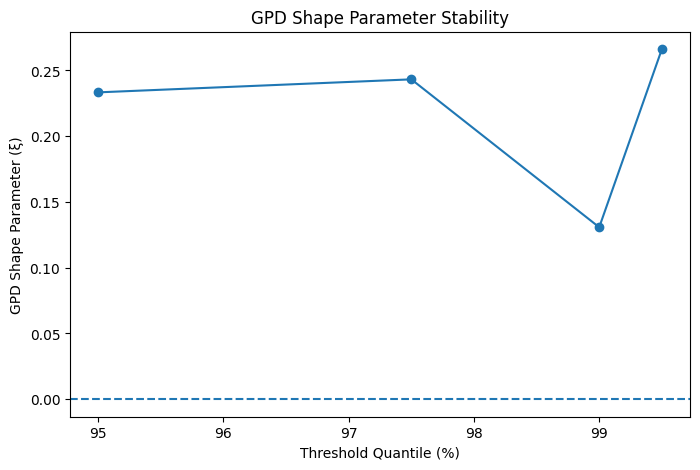

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    gpd_results["Quantile"] * 100,
    gpd_results["Shape"],
    marker="o"
)

plt.axhline(0, linestyle="--")

plt.xlabel("Threshold Quantile (%)")
plt.ylabel("GPD Shape Parameter (ξ)")
plt.title("GPD Shape Parameter Stability")

plt.show()

In [ ]:
##  Calculating Extreme values for EVT with threshold fixed as 97.5%

n = 6538
threshold = 0.025186
exceedances = 164
xi = 0.243224
beta = 0.009486

import numpy as np
import pandas as pd

# Parameters from the selected 97.5% threshold GPD
u = threshold
Nu = exceedances
xi = 0.243224
beta = 0.009486
n = 6538

# Confidence levels
confidence_levels = [0.99, 0.995, 0.999, 0.9999]

# EVT VaR calculation
evt_results = []

for p in confidence_levels:
    tail_probability = (n / Nu) * (1 - p)

    var = u + (beta / xi) * (
        tail_probability ** (-xi) - 1
    )

    evt_results.append({
        "Confidence": p,
        "EVT_VaR": var,
        "EVT_VaR_%": var * 100
    })

evt_results = pd.DataFrame(evt_results)

evt_results

,Confidence,EVT_VaR,EVT_VaR_%
0,0.9900,0.034962,3.496248
1,0.9950,0.043920,4.391973
2,0.9990,0.071582,7.158221
3,0.9999,0.135694,13.569418


In [ ]:
from scipy.stats import norm

# Mean and standard deviation of the loss series
mu = loss.mean()
sigma = loss.std()

confidence_levels = [0.99, 0.995, 0.999, 0.9999]

gaussian_results = []

for p in confidence_levels:
    z = norm.ppf(p)

    gaussian_var = mu + z * sigma

    gaussian_results.append({
        "Confidence": p,
        "Gaussian_VaR": gaussian_var,
        "Gaussian_VaR_%": gaussian_var * 100
    })

gaussian_results = pd.DataFrame(gaussian_results)

gaussian_results

,Confidence,Gaussian_VaR,Gaussian_VaR_%
0,0.9900,0.028122,2.812246
1,0.9950,0.031171,3.117129
2,0.9990,0.037458,3.745763
3,0.9999,0.045142,4.514178


In [ ]:
historical_results = []

for p in confidence_levels:

    historical_var = loss.quantile(p)

    historical_results.append({
        "Confidence": p,
        "Historical_VaR": historical_var,
        "Historical_VaR_%": historical_var * 100
    })

historical_results = pd.DataFrame(historical_results)

historical_results

,Confidence,Historical_VaR,Historical_VaR_%
0,0.9900,0.034650,3.465030
1,0.9950,0.044868,4.486827
2,0.9990,0.074590,7.459024
3,0.9999,0.107879,10.787884


In [ ]:
comparison = evt_results.merge(
    gaussian_results,
    on="Confidence"
)

comparison["Difference"] = (
    comparison["EVT_VaR"] -
    comparison["Gaussian_VaR"]
)

comparison["Gaussian_Underestimation_%"] = (
    comparison["Difference"] /
    comparison["Gaussian_VaR"]
) * 100

comparison = (
    historical_results
    .merge(gaussian_results, on="Confidence")
    .merge(evt_results, on="Confidence")
)
comparison["EVT_vs_Historical_%"] = (
    (comparison["EVT_VaR"] - comparison["Historical_VaR"])
    / comparison["Historical_VaR"]
) * 100

comparison["EVT_vs_Gaussian_%"] = (
    (comparison["EVT_VaR"] - comparison["Gaussian_VaR"])
    / comparison["Gaussian_VaR"]
) * 100

comparison

,Confidence,Historical_VaR,Historical_VaR_%,Gaussian_VaR,Gaussian_VaR_%,EVT_VaR,EVT_VaR_%,EVT_vs_Historical_%,EVT_vs_Gaussian_%
0,0.9900,0.034650,3.465029,0.028122,2.812246,0.034962,3.496248,0.900953,24.322248
1,0.9950,0.044868,4.486810,0.031171,3.117129,0.043920,4.391973,-2.113674,40.898045
2,0.9990,0.074590,7.459020,0.037458,3.745763,0.071582,7.158221,-4.032692,91.101822
3,0.9999,0.107879,10.787939,0.045142,4.514178,0.135694,13.569418,25.783230,200.595555


In [ ]:
###Backtest
# 80/20 chronological split
split_index = int(len(loss) * 0.80)

train_loss = loss.iloc[:split_index]
test_loss = loss.iloc[split_index:]

print("Training observations:", len(train_loss))
print("Testing observations:", len(test_loss))

Training observations: 5230
Testing observations: 1308


In [ ]:
##Historical Train
confidence_levels = [0.99, 0.995, 0.999, 0.9999]

historical_train = {}

for p in confidence_levels:
    historical_train[p] = train_loss.quantile(p)


##Gaussian Train
from scipy.stats import norm

train_mu = train_loss.mean()
train_sigma = train_loss.std()

gaussian_train = {}

for p in confidence_levels:
    gaussian_train[p] = (
        train_mu + norm.ppf(p) * train_sigma
    )


##EVT Train
from scipy.stats import genpareto

evt_threshold = train_loss.quantile(0.975)

excesses_train = train_loss[
    train_loss > evt_threshold
] - evt_threshold

Nu_train = len(excesses_train)
n_train = len(train_loss)

xi_train, loc_train, beta_train = genpareto.fit(
    excesses_train,
    floc=0
)

evt_train = {}

for p in confidence_levels:

    tail_probability = (
        n_train / Nu_train
    ) * (1 - p)

    var = evt_threshold + (
        beta_train / xi_train
    ) * (
        tail_probability ** (-xi_train) - 1
    )

    evt_train[p] = var



backtest_results = []

for p in confidence_levels:

    historical_var = historical_train[p]
    gaussian_var = gaussian_train[p]
    evt_var = evt_train[p]

    actual_loss = test_loss

    historical_breaches = (
        actual_loss > historical_var
    ).sum()

    gaussian_breaches = (
        actual_loss > gaussian_var
    ).sum()

    evt_breaches = (
        actual_loss > evt_var
    ).sum()

    n_test = len(test_loss)

    backtest_results.append({
        "Confidence": p,

        "Historical_VaR": historical_var,
        "Gaussian_VaR": gaussian_var,
        "EVT_VaR": evt_var,

        "Historical_Breaches": historical_breaches,
        "Gaussian_Breaches": gaussian_breaches,
        "EVT_Breaches": evt_breaches,

        "Historical_Breach_Rate":
            historical_breaches / n_test,

        "Gaussian_Breach_Rate":
            gaussian_breaches / n_test,

        "EVT_Breach_Rate":
            evt_breaches / n_test,

        "Expected_Breach_Rate":
            1 - p
    })

backtest_results = pd.DataFrame(backtest_results)

backtest_results

,Confidence,Historical_VaR,Gaussian_VaR,EVT_VaR,Historical_Breaches,Gaussian_Breaches,EVT_Breaches,Historical_Breach_Rate,Gaussian_Breach_Rate,EVT_Breach_Rate,Expected_Breach_Rate
0,0.9900,0.035667,0.028991,0.036248,8,17,7,0.006116,0.012997,0.005352,0.0100
1,0.9950,0.045998,0.032126,0.045930,2,12,2,0.001529,0.009174,0.001529,0.0050
2,0.9990,0.080356,0.038590,0.075450,0,6,0,0.000000,0.004587,0.000000,0.0010
3,0.9999,0.109482,0.046491,0.142406,0,2,0,0.000000,0.001529,0.000000,0.0001


In [ ]:
print("Start date:", loss.index.min())
print("End date:", loss.index.max())
print("Number of observations:", len(loss))

print(loss.head())
print(loss.tail())

Start date: 2000-01-04 00:00:00
End date: 2025-12-31 00:00:00
Number of observations: 6538
Date
2000-01-04    0.039892
2000-01-05   -0.001788
2000-01-06    0.016202
2000-01-07   -0.056452
2000-01-10   -0.003425
Name: Log Returns, dtype: float64
Date
2025-12-24   -0.003512
2025-12-26    0.000101
2025-12-29    0.003570
2025-12-30    0.001222
2025-12-31    0.007436
Name: Log Returns, dtype: float64


In [ ]:
# Top 20 worst daily losses
worst_losses = loss.sort_values(ascending=False).head(20)

print("Top 20 Worst Daily Losses:")
print(worst_losses)

Top 20 Worst Daily Losses:
Date
2020-03-16    0.115886
2008-10-15    0.103638
2020-03-12    0.100569
2008-12-01    0.092749
2008-09-29    0.081603
2020-03-09    0.081313
2008-11-20    0.077133
2008-10-09    0.072398
2011-08-08    0.067341
2008-11-19    0.066224
2025-04-04    0.060327
2020-06-11    0.059377
2000-04-14    0.058893
2008-11-06    0.057006
2008-10-22    0.055993
2009-01-20    0.054230
2001-09-17    0.053663
2008-10-06    0.052276
2008-10-24    0.052046
2020-03-18    0.051960
Name: Log Returns, dtype: float64


In [ ]:
# Corresponding returns
print("\nWorst 20 Daily Returns:")
print((-worst_losses).sort_values())


Worst 20 Daily Returns:
Date
2020-03-16   -0.115886
2008-10-15   -0.103638
2020-03-12   -0.100569
2008-12-01   -0.092749
2008-09-29   -0.081603
2020-03-09   -0.081313
2008-11-20   -0.077133
2008-10-09   -0.072398
2011-08-08   -0.067341
2008-11-19   -0.066224
2025-04-04   -0.060327
2020-06-11   -0.059377
2000-04-14   -0.058893
2008-11-06   -0.057006
2008-10-22   -0.055993
2009-01-20   -0.054230
2001-09-17   -0.053663
2008-10-06   -0.052276
2008-10-24   -0.052046
2020-03-18   -0.051960
Name: Log Returns, dtype: float64


In [ ]:
crash_windows = {
    "Dot-com Crash": ("2000-01-01", "2002-12-31"),
    "Global Financial Crisis": ("2007-01-01", "2009-12-31"),
    "COVID Crash": ("2020-02-01", "2020-04-30"),
    "2022 Bear Market": ("2022-01-01", "2022-12-31")
}

crash_results = []

for crash, (start, end) in crash_windows.items():
    crash_data = loss.loc[start:end]

    worst_date = crash_data.idxmax()
    worst_loss = crash_data.max()

    crash_results.append({
        "Crash": crash,
        "Worst Date": worst_date,
        "Worst Daily Loss": worst_loss,
        "Worst Daily Return": -worst_loss,
        "Observations": len(crash_data)
    })

crash_results = pd.DataFrame(crash_results)

print(crash_results)

                     Crash Worst Date  Worst Daily Loss  Worst Daily Return  \
0            Dot-com Crash 2000-04-14          0.058893           -0.058893   
1  Global Financial Crisis 2008-10-15          0.103638           -0.103638   
2              COVID Crash 2020-03-16          0.115886           -0.115886   
3         2022 Bear Market 2022-09-13          0.044456           -0.044456   

   Observations  
0           751  
1           756  
2            62  
3           251  


In [ ]:
import numpy as np

for crash, (start, end) in crash_windows.items():
    crash_returns = -loss.loc[start:end]

    cumulative_return = np.exp(crash_returns.sum()) - 1

    print(f"{crash}:")
    print(f"  Cumulative Return: {cumulative_return:.2%}")
    print(f"  Worst Daily Loss: {loss.loc[start:end].max():.2%}")
    print()

Dot-com Crash:
  Cumulative Return: -36.93%
  Worst Daily Loss: 5.89%

Global Financial Crisis:
  Cumulative Return: -16.03%
  Worst Daily Loss: 10.36%

COVID Crash:
  Cumulative Return: -9.18%
  Worst Daily Loss: 11.59%

2022 Bear Market:
  Cumulative Return: -18.18%
  Worst Daily Loss: 4.45%



In [ ]:
# Historical crash worst losses
crash_validation = crash_results[
    ["Crash", "Worst Date", "Worst Daily Loss"]
].copy()

# Add VaR estimates from the models
for p in confidence_levels:
    evt_var = evt_results.loc[
        evt_results["Confidence"] == p, "EVT_VaR"
    ].iloc[0]

    gaussian_var = gaussian_results.loc[
        gaussian_results["Confidence"] == p, "Gaussian_VaR"
    ].iloc[0]

    historical_var = historical_results.loc[
        historical_results["Confidence"] == p, "Historical_VaR"
    ].iloc[0]

    print(f"\n{'='*60}")
    print(f"Confidence Level: {p:.2%}")
    print(f"EVT VaR:        {evt_var:.2%}")
    print(f"Gaussian VaR:   {gaussian_var:.2%}")
    print(f"Historical VaR: {historical_var:.2%}")

    print("\nCrash worst losses:")
    print(crash_validation[["Crash", "Worst Daily Loss"]])


Confidence Level: 99.00%
EVT VaR:        3.50%
Gaussian VaR:   2.81%
Historical VaR: 3.47%

Crash worst losses:
                     Crash  Worst Daily Loss
0            Dot-com Crash          0.058893
1  Global Financial Crisis          0.103638
2              COVID Crash          0.115886
3         2022 Bear Market          0.044456

Confidence Level: 99.50%
EVT VaR:        4.39%
Gaussian VaR:   3.12%
Historical VaR: 4.49%

Crash worst losses:
                     Crash  Worst Daily Loss
0            Dot-com Crash          0.058893
1  Global Financial Crisis          0.103638
2              COVID Crash          0.115886
3         2022 Bear Market          0.044456

Confidence Level: 99.90%
EVT VaR:        7.16%
Gaussian VaR:   3.75%
Historical VaR: 7.46%

Crash worst losses:
                     Crash  Worst Daily Loss
0            Dot-com Crash          0.058893
1  Global Financial Crisis          0.103638
2              COVID Crash          0.115886
3         2022 Bear Market     

In [ ]:
validation_rows = []

for _, crash in crash_validation.iterrows():

    for p in confidence_levels:

        actual = crash["Worst Daily Loss"]

        evt_var = evt_results.loc[
            evt_results["Confidence"] == p,
            "EVT_VaR"
        ].iloc[0]

        gaussian_var = gaussian_results.loc[
            gaussian_results["Confidence"] == p,
            "Gaussian_VaR"
        ].iloc[0]

        historical_var = historical_results.loc[
            historical_results["Confidence"] == p,
            "Historical_VaR"
        ].iloc[0]

        validation_rows.append({
            "Crash": crash["Crash"],
            "Confidence": p,
            "Actual_Worst_Loss": actual,
            "EVT_VaR": evt_var,
            "Gaussian_VaR": gaussian_var,
            "Historical_VaR": historical_var,
            "EVT_Ratio": actual / evt_var,
            "Gaussian_Ratio": actual / gaussian_var,
            "Historical_Ratio": actual / historical_var
        })

crash_var_validation = pd.DataFrame(validation_rows)

print(crash_var_validation)

                      Crash  Confidence  Actual_Worst_Loss   EVT_VaR  \
0             Dot-com Crash      0.9900           0.058893  0.034962   
1             Dot-com Crash      0.9950           0.058893  0.043920   
2             Dot-com Crash      0.9990           0.058893  0.071582   
3             Dot-com Crash      0.9999           0.058893  0.135694   
4   Global Financial Crisis      0.9900           0.103638  0.034962   
5   Global Financial Crisis      0.9950           0.103638  0.043920   
6   Global Financial Crisis      0.9990           0.103638  0.071582   
7   Global Financial Crisis      0.9999           0.103638  0.135694   
8               COVID Crash      0.9900           0.115886  0.034962   
9               COVID Crash      0.9950           0.115886  0.043920   
10              COVID Crash      0.9990           0.115886  0.071582   
11              COVID Crash      0.9999           0.115886  0.135694   
12         2022 Bear Market      0.9900           0.044456  0.03

In [ ]:
comparison_extreme = comparison.copy()

comparison_extreme["EVT_vs_Gaussian_%"] = (
    (comparison_extreme["EVT_VaR"] -
     comparison_extreme["Gaussian_VaR"])
    / comparison_extreme["Gaussian_VaR"]
) * 100

comparison_extreme[
    [
        "Confidence",
        "Gaussian_VaR_%",
        "EVT_VaR_%",
        "EVT_vs_Gaussian_%"
    ]
]

,Confidence,Gaussian_VaR_%,EVT_VaR_%,EVT_vs_Gaussian_%
0,0.9900,2.812246,3.496248,24.322248
1,0.9950,3.117129,4.391973,40.898045
2,0.9990,3.745763,7.158221,91.101822
3,0.9999,4.514178,13.569418,200.595555
